(465, 992, 1472) (465, 992, 1472)


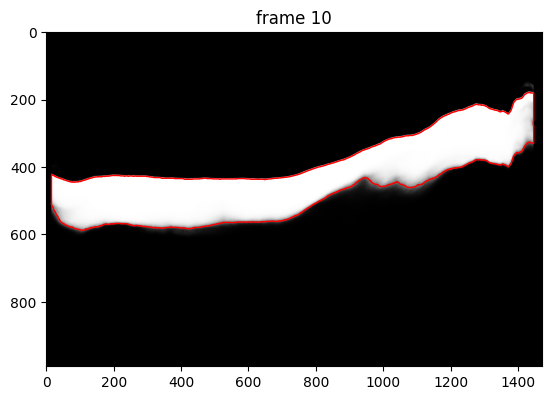

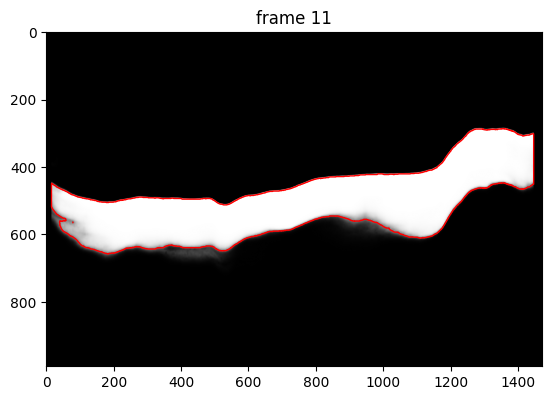

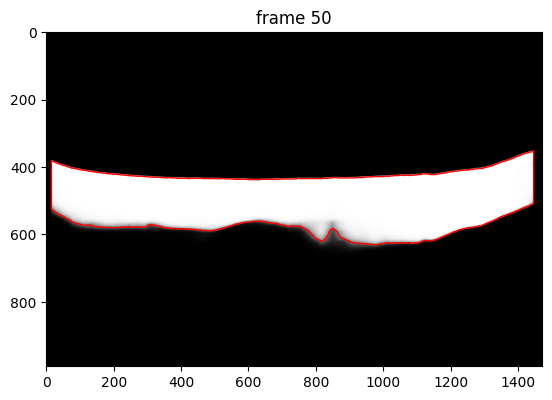

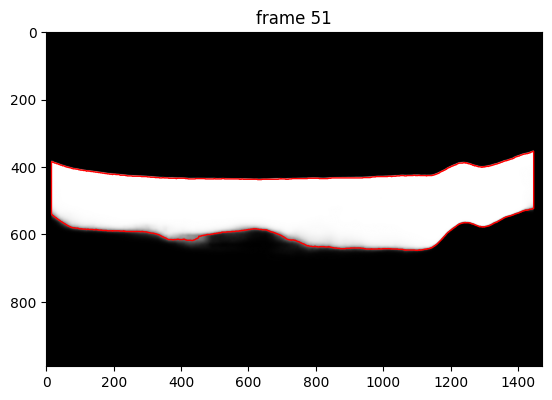

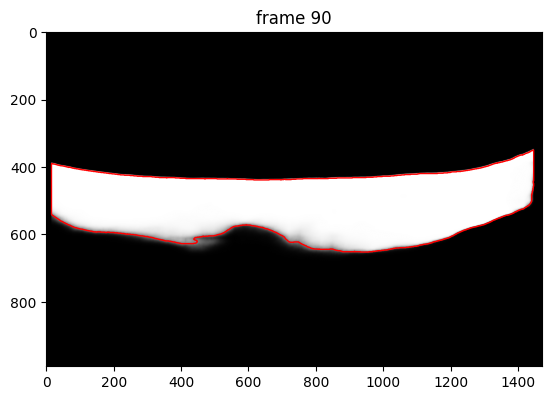

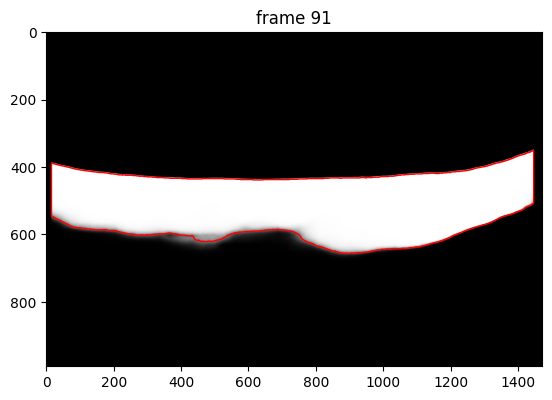

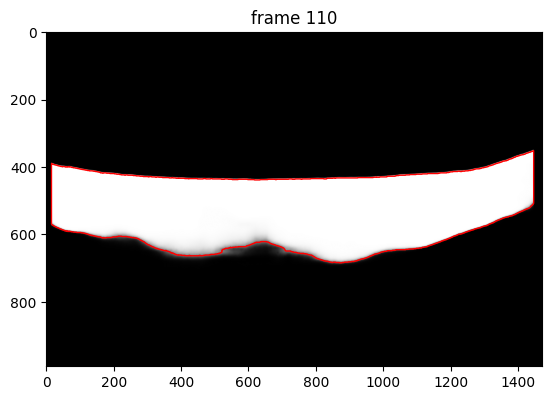

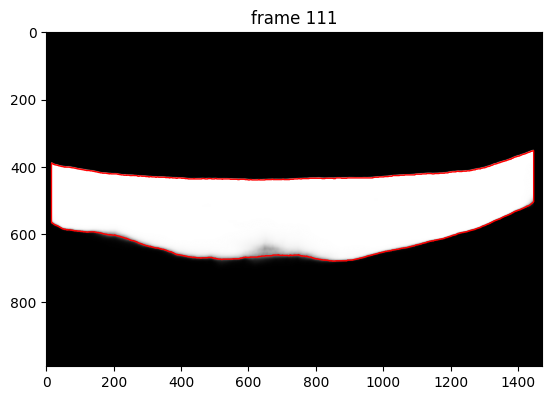

In [12]:
from pathlib import Path
from ocularrigidity.data.io import load_mask
from ocularrigidity.scripts.registration.cascade_v9_plex import load_probs
import matplotlib.pyplot as plt
import numpy as np
path_general = Path("E:/SANSORI/06_210831001/210831001post_rigidity/210831001post_rigidity_OD2/RawImages/registered_cascade_v9_plex_full")

idx_m = [10,11, 50,51, 90,91, 110,111]
path_mask = path_general / "mask.npz"
path_prob = path_general / "prob.npz"

mask = load_mask(path_mask)
prob = load_probs(path_prob) / 255.0  # (T, H, W) uint8 compresse zstd -> probabilite [0, 1]
print(prob.shape, mask.shape)

for idx_plot in idx_m:
    plt.imshow(prob[idx_plot], cmap="gray", vmin=0, vmax=1)
    plt.contour(mask[idx_plot], levels=[0.5], colors="red", linewidths=1)
    plt.title(f"frame {idx_plot}")
    plt.show()


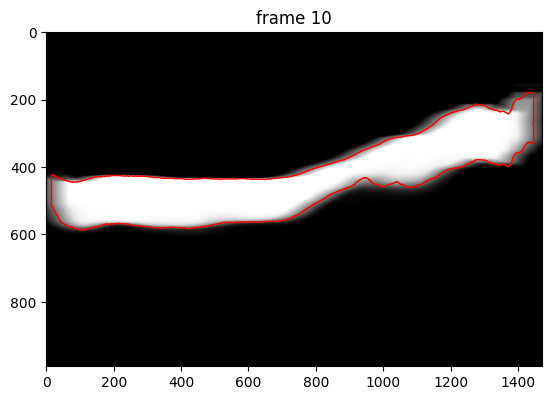

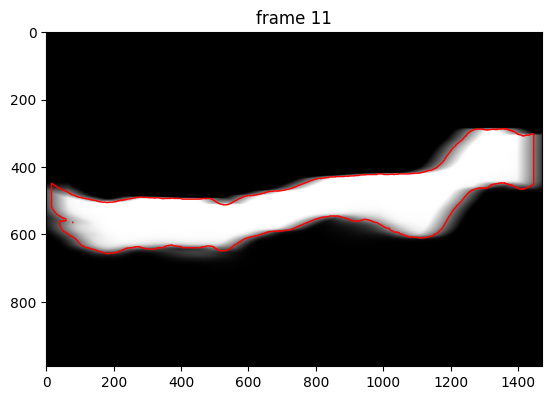

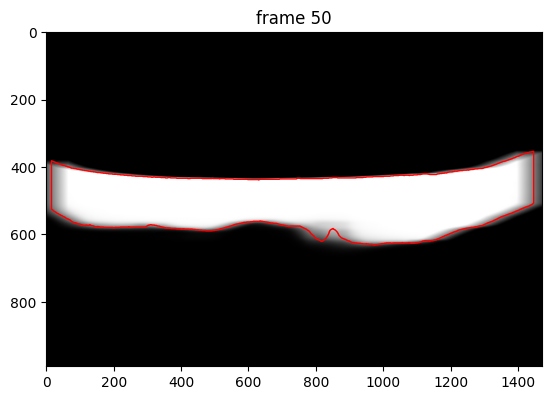

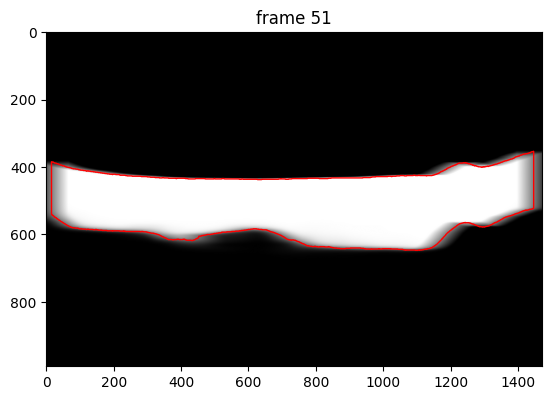

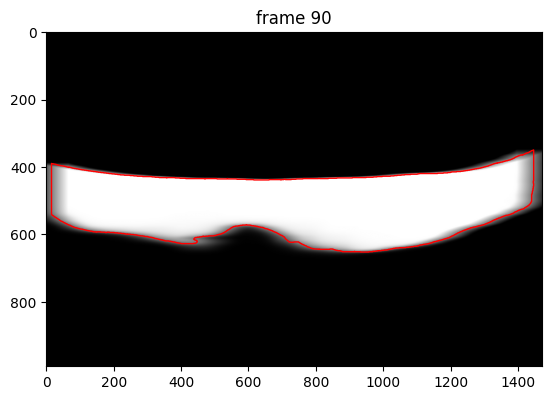

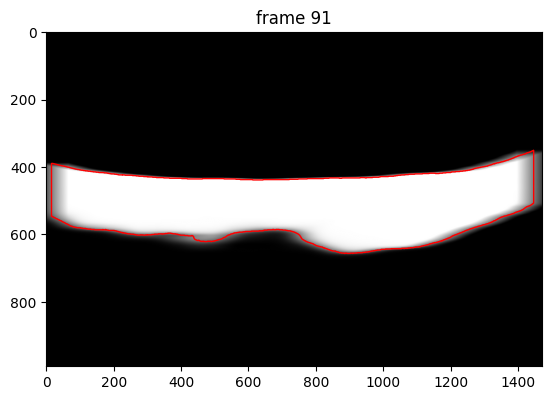

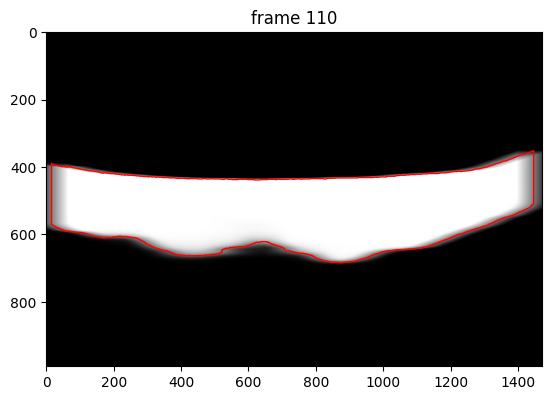

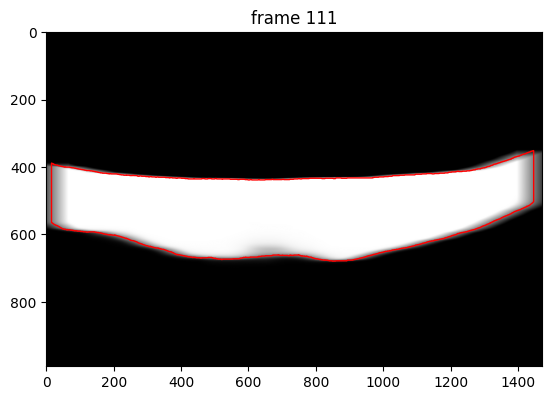

In [13]:
window_size = 100
kernel = np.ones(window_size) / window_size
#smooth_prob = np.convolve(prob, kernel, mode='same',axis=2)

# Output array
result = np.empty((prob.shape[0], prob.shape[1], prob.shape[2]))

# Convolve along axis=2 (third dimension)
for i in range(prob.shape[0]):
    for j in range(prob.shape[1]):
        result[i, j, :] = np.convolve(prob[i, j, :], kernel, mode='same')

for idx_plot in idx_m:
    plt.imshow(result[idx_plot], cmap="gray", vmin=0, vmax=1)
    plt.contour(mask[idx_plot], levels=[0.5], colors="red", linewidths=1)
    plt.title(f"frame {idx_plot}")
    plt.show()